In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
    ("tensorflow", "tensorflow==2.11.0",    "tensorflow==2.16.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# [DEMO] Bài 3: Phát hiện Tấn công ICS bằng Mô hình LSTM Có Giám sát

> **File này là bản DEMO hoàn chỉnh** — tất cả code đã được điền sẵn và có thể chạy ngay.
> Học viên hãy chạy từng cell theo thứ tự, quan sát kết quả, rồi tự thực hành trong `b2_lstm_exercise.ipynb`.

## Mục tiêu
- Xây dựng mô hình **LSTM có giám sát** cho bài toán phân loại chuỗi thời gian
- Tạo dữ liệu chuỗi bằng **cửa sổ trượt** (sliding window) từ dữ liệu cảm biến
- Huấn luyện LSTM classifier với **class_weight** để xử lý mất cân bằng nhãn
- Tinh chỉnh **ngưỡng quyết định** (threshold) để tối ưu F1-score

## Phần 1: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                              confusion_matrix, roc_auc_score, roc_curve,
                              ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)
plt.rcParams['figure.figsize'] = (13, 5)
print(f'TensorFlow version: {tf.__version__}')
print('Thư viện đã được import thành công!')

TensorFlow version: 2.19.0
Thư viện đã được import thành công!


## Phần 2: Tải và Chuẩn bị Dữ liệu

In [2]:
train_df = pd.read_csv('data/BATADAL/train_dataset.csv', index_col=0)
test1_df = pd.read_csv('data/BATADAL/test_dataset_1.csv', index_col=0)
test2_df = pd.read_csv('data/BATADAL/test_dataset_2.csv', index_col=0)

feature_cols = [c for c in train_df.columns if c not in ['DATETIME', 'ATT_FLAG']]
n_features   = len(feature_cols)

# Chuẩn hóa: fit trên test1 (có nhãn), transform cả test1 và test2
scaler        = StandardScaler()
X_test1_sc    = scaler.fit_transform(test1_df[feature_cols].values)
X_test2_sc    = scaler.transform(test2_df[feature_cols].values)
y_test1       = test1_df['ATT_FLAG'].values
y_test2       = test2_df['ATT_FLAG'].values

print(f'Test 1: {test1_df.shape[0]} mẫu (Normal={(y_test1==0).sum()}, Attack={(y_test1==1).sum()})')
print(f'Test 2: {test2_df.shape[0]} mẫu (Normal={(y_test2==0).sum()}, Attack={(y_test2==1).sum()})')
print(f'Số đặc trưng: {n_features}')

Test 1: 18433 mẫu (Normal=16465, Attack=1968)
Test 2: 10081 mẫu (Normal=8453, Attack=1628)
Số đặc trưng: 43


## Phần 3: Tạo Chuỗi bằng Cửa sổ Trượt (Sliding Window)

Mỗi chuỗi gồm `WINDOW_SIZE=30` bước thời gian liên tiếp.
Nhãn của chuỗi = **1** nếu BẤT KỲ bước thời gian nào trong cửa sổ là tấn công.

In [3]:
WINDOW_SIZE = 30
STEP        = 5   # Bước trượt (stride) khi tạo chuỗi

def create_sequences(X, y, window_size=30, step=1):
    """Tạo chuỗi thời gian với nhãn majority vote."""
    sequences, labels = [], []
    for i in range(0, len(X) - window_size + 1, step):
        seq   = X[i : i + window_size]
        label = 1 if y[i : i + window_size].sum() > 0 else 0
        sequences.append(seq)
        labels.append(label)
    return np.array(sequences, dtype=np.float32), np.array(labels, dtype=np.int32)

# Tạo chuỗi từ test1 (dùng làm tập train supervised)
X_seq, y_seq = create_sequences(X_test1_sc, y_test1, WINDOW_SIZE, STEP)

# Chia train/val
X_tr, X_val, y_tr, y_val = train_test_split(
    X_seq, y_seq, test_size=0.3, random_state=42, stratify=y_seq
)

# Tạo chuỗi từ test2 (held-out, step=1)
X_test2_seq, y_test2_seq = create_sequences(X_test2_sc, y_test2, WINDOW_SIZE, step=1)

print(f'Chuỗi train : {X_tr.shape}  nhãn attack={(y_tr==1).sum()} ({100*(y_tr==1).mean():.1f}%)')
print(f'Chuỗi val   : {X_val.shape}  nhãn attack={(y_val==1).sum()} ({100*(y_val==1).mean():.1f}%)')
print(f'Chuỗi test2 : {X_test2_seq.shape} nhãn attack={(y_test2_seq==1).sum()} ({100*(y_test2_seq==1).mean():.1f}%)')

Chuỗi train : (2576, 30, 43)  nhãn attack=304 (11.8%)
Chuỗi val   : (1105, 30, 43)  nhãn attack=130 (11.8%)
Chuỗi test2 : (10052, 30, 43) nhãn attack=1831 (18.2%)


## Phần 4: Xây dựng Kiến trúc LSTM

**Kiến trúc LSTM Classifier:**
- Input: (batch, WINDOW_SIZE=30, n_features=43)
- LSTM(64, return_sequences=True) → mỗi bước thời gian đều có output
- Dropout(0.3)
- LSTM(32) → chỉ output bước cuối
- Dropout(0.3)
- Dense(16, relu) → bottleneck
- Dense(1, sigmoid) → xác suất tấn công

In [4]:
def build_lstm_classifier(n_timesteps, n_features, lstm_units=64):
    model = Sequential([
        LSTM(lstm_units, return_sequences=True,
             input_shape=(n_timesteps, n_features)),
        Dropout(0.3),
        LSTM(lstm_units // 2),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='LSTM_Classifier')

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_lstm_classifier(WINDOW_SIZE, n_features)
model.summary()

Model: "LSTM_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        27,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,609 (158.63 KB)

 Trainable params: 40,609 (158.63 KB)

 Non-trainable params: 0 (0.00 B)

## Phần 5: Huấn luyện Mô hình

In [5]:
# Class weight để xử lý mất cân bằng nhãn
pos_weight   = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
class_weight = {0: 1.0, 1: float(pos_weight)}
print(f'Class weight: normal=1.0, attack={pos_weight:.2f}')

callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True,
                  monitor='val_loss', verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=5,
                      min_lr=1e-6, verbose=0)
]

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)
print(f'\nHuấn luyện kết thúc ở epoch {len(history.history["loss"])}')

Class weight: normal=1.0, attack=7.47
Epoch 1/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6516 - loss: 1.0425 - val_accuracy: 0.9448 - val_loss: 0.2780 - learning_rate: 0.0010
Epoch 2/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9502 - loss: 0.5063 - val_accuracy: 0.9475 - val_loss: 0.1869 - learning_rate: 0.0010
Epoch 3/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9548 - loss: 0.3176 - val_accuracy: 0.9756 - val_loss: 0.0863 - learning_rate: 0.0010
Epoch 4/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9787 - loss: 0.1784 - val_accuracy: 0.9575 - val_loss: 0.1573 - learning_rate: 0.0010
Epoch 5/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9672 - loss: 0.1631 - val_accuracy: 0.9729 - val_loss: 0.0916 - learning_rate: 0.0010
Epoch 6/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9782 - loss: 0.1409 - val_accuracy: 0.9864 - val_loss: 0.0544 - learning_rate: 0.0010
Epoch 7/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - acc

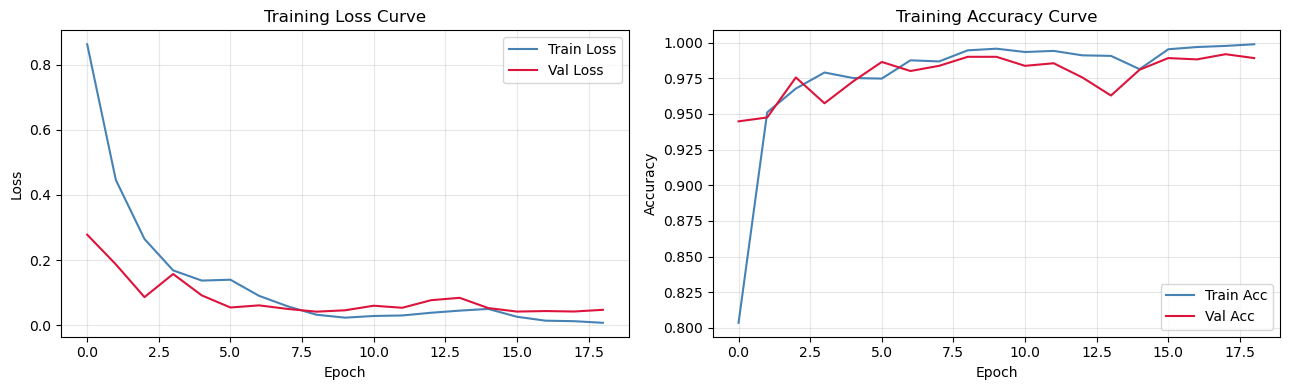

In [6]:
# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='crimson')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss Curve'); axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'],     label='Train Acc', color='steelblue')
axes[1].plot(history.history['val_accuracy'], label='Val Acc',   color='crimson')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training Accuracy Curve'); axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## Phần 6: Tinh chỉnh Ngưỡng và Đánh giá

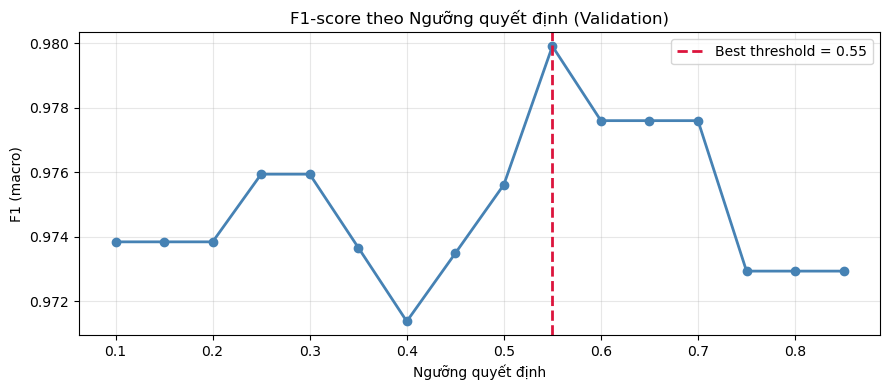


=== LSTM Classifier (Val, thr=0.55) ===
  F1 (macro): 0.9799 | Precision: 0.9919 | Recall: 0.9385
  AUC-ROC  : 0.9936
  TN=974, FP=1, FN=8, TP=122


In [7]:
# Tìm ngưỡng tối ưu trên tập val
y_prob_val  = model.predict(X_val, verbose=0).ravel()
thresholds  = np.arange(0.1, 0.9, 0.05)
f1s         = [f1_score(y_val, (y_prob_val > t).astype(int),
                        average='macro', zero_division=0)
               for t in thresholds]
best_thr    = float(thresholds[np.argmax(f1s)])

plt.figure(figsize=(9, 4))
plt.plot(thresholds, f1s, 'o-', color='steelblue', linewidth=2)
plt.axvline(best_thr, color='crimson', linestyle='--', linewidth=2,
            label=f'Best threshold = {best_thr:.2f}')
plt.xlabel('Ngưỡng quyết định'); plt.ylabel('F1 (macro)')
plt.title('F1-score theo Ngưỡng quyết định (Validation)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# Đánh giá trên val
y_pred_val = (y_prob_val > best_thr).astype(int)
f1  = f1_score(y_val, y_pred_val, average='macro', zero_division=0)
pre = precision_score(y_val, y_pred_val, pos_label=1, zero_division=0)
rec = recall_score(y_val, y_pred_val, pos_label=1, zero_division=0)
auc = roc_auc_score(y_val, y_prob_val)
print(f'\n=== LSTM Classifier (Val, thr={best_thr:.2f}) ===')
print(f'  F1 (macro): {f1:.4f} | Precision: {pre:.4f} | Recall: {rec:.4f}')
print(f'  AUC-ROC  : {auc:.4f}')
cm = confusion_matrix(y_val, y_pred_val)
print(f'  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

## Phần 7: Đánh giá trên Test 2 (Held-out)

=== LSTM Classifier (Test2, thr=0.55) ===
  F1 (macro): 0.7586 | Precision: 0.9368 | Recall: 0.4211
  AUC-ROC  : 0.7592


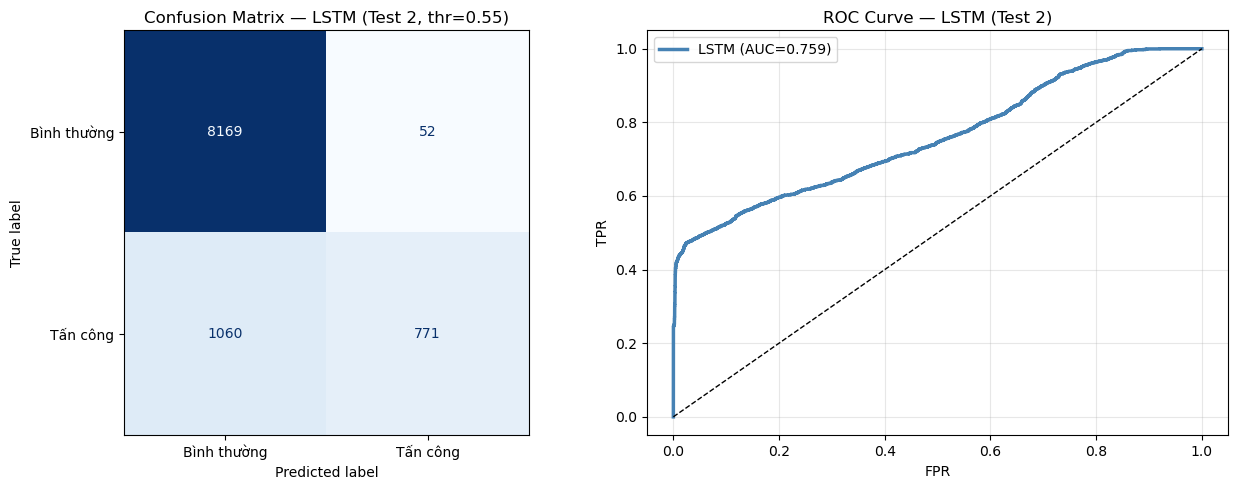

In [8]:
y_prob_test2 = model.predict(X_test2_seq, verbose=0).ravel()
y_pred_test2 = (y_prob_test2 > best_thr).astype(int)

f1  = f1_score(y_test2_seq, y_pred_test2, average='macro', zero_division=0)
pre = precision_score(y_test2_seq, y_pred_test2, pos_label=1, zero_division=0)
rec = recall_score(y_test2_seq, y_pred_test2, pos_label=1, zero_division=0)
auc = roc_auc_score(y_test2_seq, y_prob_test2)
print(f'=== LSTM Classifier (Test2, thr={best_thr:.2f}) ===')
print(f'  F1 (macro): {f1:.4f} | Precision: {pre:.4f} | Recall: {rec:.4f}')
print(f'  AUC-ROC  : {auc:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(y_test2_seq, y_pred_test2)
ConfusionMatrixDisplay(cm, display_labels=['Bình thường', 'Tấn công']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Confusion Matrix — LSTM (Test 2, thr={best_thr:.2f})')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test2_seq, y_prob_test2)
axes[1].plot(fpr, tpr, color='steelblue', linewidth=2.5,
             label=f'LSTM (AUC={auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', linewidth=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve — LSTM (Test 2)'); axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## Kết luận Demo

**Ưu điểm của LSTM Có Giám sát:**
- Học được **phụ thuộc thời gian dài** (long-term temporal dependency)
- Độ chính xác cao hơn LSTM-AE khi có dữ liệu nhãn
- Ngưỡng quyết định có thể tinh chỉnh để cân bằng Precision/Recall

**Nhược điểm:**
- Cần dữ liệu tấn công có nhãn để huấn luyện
- Thời gian huấn luyện lâu hơn phương pháp truyền thống
- Có thể bị overfitting nếu tập train nhỏ

---
**Bước tiếp theo:** Mở `b3_lstm_exercise.ipynb` và tự điền vào các ô `???`.